# BÀI THỰC HÀNH 04: HỒI QUY TUYẾN TÍNH & HỒI QUY LOGISTIC
## BÀI TOÁN 2: HỒI QUY LOGISTIC – CHẨN ĐOÁN BỆNH TIỂU ĐƯỜNG (DIABETES CLASSIFICATION)

* **Môn học:** Học máy (Machine Learning)
* **Sinh viên thực hiện:** Nguyễn Đức Duy
* **Mã số sinh viên (MSSV):** 65130628
* **Lớp:** Trí tuệ Nhân tạo - KHMT
* **Môi trường:** Python 3.10+, JupyterLab, Scikit-learn, Pandas, NumPy, Matplotlib, Seaborn

---
### I. BỐI CẢNH BÀI TOÁN PHÂN LOẠI Y TẾ & CƠ SỞ TOÁN HỌC
Tập dữ liệu Pima Indians Diabetes Database khảo sát các chỉ số sức khỏe của cộng đồng phụ nữ bản địa Pima nhằm chẩn đoán sớm bệnh đái tháo đường. Trong y tế, việc chẩn đoán không chỉ dừng lại ở độ chính xác tổng quát (Accuracy) mà còn gắn liền với **chi phí sai lầm sinh mạng**: bỏ sót một bệnh nhân đang nhiễm bệnh nguy hiểm hơn rất nhiều so với việc chỉ định xét nghiệm thêm cho một người khỏe mạnh.

Hồi quy Logistic ước lượng xác suất hậu nghiệm thông qua hàm **Sigmoid**:
$$P(Y = 1|X) = \sigma(w^T X + b) = \frac{1}{1 + e^{-(w^T X + b)}}$$

Mô hình được tối ưu bằng cách cực tiểu hóa hàm mất mát **Cross-Entropy (Log-loss)**:
$$J(w) = -\frac{1}{N} \sum_{i=1}^N \left[ y_i \log(\hat{p}_i) + (1 - y_i) \log(1 - \hat{p}_i) \right]$$


### Khám phá dữ liệu & Phát hiện lỗi logic thực tế
* Tập dữ liệu gồm 768 bệnh nhân với 8 thuộc tính đo lường lâm sàng và 1 biến nhãn `Outcome` (1: Mắc bệnh, 0: Khỏe mạnh).
* **Phát hiện lỗi logic thực tế:** Các thuộc tính sinh học sống như `Glucose`, `BloodPressure`, `SkinThickness`, `Insulin`, `BMI` xuất hiện các giá trị bằng 0. Một cơ thể sống không thể có nồng độ glucose hoặc huyết áp bằng 0. Các số 0 này bản chất là **dữ liệu bị thiếu (Missing Values)** trong quá trình nhập liệu lâm sàng.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
%matplotlib inline

# Đọc dữ liệu từ raw
df_diabetes = pd.read_csv('../data/raw/diabetes.csv')

print(f"Kích thước dữ liệu: {df_diabetes.shape[0]} bệnh nhân, {df_diabetes.shape[1]} thuộc tính")
display(df_diabetes.head())

# Thống kê số lượng giá trị 0 bất thường ở các cột sinh học
zero_invalid_cols = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
print("\nThống kê số lượng giá trị 0 bất thường (Missing Values ngụy trang):")
for col in zero_invalid_cols:
    count_zero = (df_diabetes[col] == 0).sum()
    pct_zero = count_zero / len(df_diabetes) * 100
    print(f"  - Cột {col:15s}: {count_zero:3d} giá trị 0 ({pct_zero:5.2f}%)")


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


Kích thước dữ liệu: 768 bệnh nhân, 9 thuộc tính

Thống kê số lượng giá trị 0 bất thường (Missing Values ngụy trang):
  - Cột Glucose        :   5 giá trị 0 ( 0.65%)
  - Cột BloodPressure  :  35 giá trị 0 ( 4.56%)
  - Cột SkinThickness  : 227 giá trị 0 (29.56%)
  - Cột Insulin        : 374 giá trị 0 (48.70%)
  - Cột BMI            :  11 giá trị 0 ( 1.43%)


### Khối 2.1: Bóc tách và phân chia tập dữ liệu có bảo toàn phân phối (Stratified Split)
* **Thực hiện:** Chia tách ma trận đặc trưng $X$ và nhãn $y$, sử dụng `train_test_split` với tham số bắt buộc `stratify=y`.
* **Ý nghĩa:** Tập dữ liệu bị mất cân bằng nhãn (~65% nhãn 0 và ~35% nhãn 1). Stratified Split đảm bảo tỷ lệ người mắc bệnh ở cả tập Train và Test là hoàn toàn đồng nhất, tránh hiện tượng lệch phân bổ nhãn gây sai lệch kết quả đánh giá.

In [2]:
from sklearn.model_selection import train_test_split

X = df_diabetes.drop(columns=['Outcome'])
y = df_diabetes['Outcome']

# Phân chia dữ liệu có bảo toàn tỷ lệ nhãn (Stratified Split)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Tỷ lệ nhãn 1 trên tập Train: {y_train.mean():.4f} ({y_train.sum()}/{len(y_train)})")
print(f"Tỷ lệ nhãn 1 trên tập Test:  {y_test.mean():.4f} ({y_test.sum()}/{len(y_test)})")


Tỷ lệ nhãn 1 trên tập Train: 0.3485 (214/614)
Tỷ lệ nhãn 1 trên tập Test:  0.3506 (54/154)


### Khối 2.2: Xử lý dữ liệu thiếu ngụy trang dưới số 0 (Imputation)
* **Thực hiện:** Bù khuyết dữ liệu thiếu bằng giá trị trung vị (**Median**). Giá trị trung vị bền vững hơn số trung bình (Mean) khi dữ liệu có độ lệch phân phối cao (như cột Insulin).
* **Ý nghĩa kiểm soát rò rỉ:** Tính median thuần túy trên tập `X_train` (chỉ xét các giá trị hợp lệ $>0$). Tuyệt đối không dùng thông tin phân phối của `X_test` để điền dữ liệu khuyết nhằm tránh Data Leakage.

In [3]:
# Tính trung vị (median) trên tập TRAIN (chỉ tính trên các giá trị hợp lệ > 0)
train_medians = {}
for col in zero_invalid_cols:
    train_medians[col] = X_train[X_train[col] != 0][col].median()

print("Giá trị Median học được thuần túy từ tập Train:")
for col, med in train_medians.items():
    print(f"  {col:15s}: {med}")

# Thay thế giá trị 0 bằng median tính từ Train cho cả hai tập
for col in zero_invalid_cols:
    X_train[col] = X_train[col].replace(0, train_medians[col])
    X_test[col] = X_test[col].replace(0, train_medians[col])

print("\nKiểm tra lại số lượng giá trị 0 sau khi bù khuyết trên X_train:")
print(X_train[zero_invalid_cols].isin([0]).sum())


Giá trị Median học được thuần túy từ tập Train:
  Glucose        : 117.0
  BloodPressure  : 72.0
  SkinThickness  : 29.0
  Insulin        : 125.0
  BMI            : 32.4

Kiểm tra lại số lượng giá trị 0 sau khi bù khuyết trên X_train:
Glucose          0
BloodPressure    0
SkinThickness    0
Insulin          0
BMI              0
dtype: int64


### Khối 2.3: Chuẩn hóa đặc trưng (Feature Scaling)
* **Thực hiện:** Chuẩn hóa toàn bộ các đặc trưng về cùng thang đo chuẩn $\mathcal{N}(0, 1)$ bằng `StandardScaler`.
* **Ý nghĩa:** Mô hình Logistic Regression sử dụng chuẩn hóa điều chuẩn (Regularization $L_2$). Nếu thang đo của các biến khác nhau (ví dụ Insulin hàng trăm, Pedigree chỉ từ 0 đến 2), trọng số của biến có độ lớn tự nhiên lớn hơn sẽ bị phạt oan ức, làm sai lệch ranh giới quyết định.

In [4]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Kỳ vọng (Mean) trên Train sau chuẩn hóa (xấp xỉ 0):", np.round(X_train_scaled.mean(axis=0), 4))
print("Độ lệch chuẩn (Std) trên Train sau chuẩn hóa (bằng 1):", np.round(X_train_scaled.std(axis=0), 4))


Kỳ vọng (Mean) trên Train sau chuẩn hóa (xấp xỉ 0): [-0. -0.  0. -0. -0.  0. -0. -0.]
Độ lệch chuẩn (Std) trên Train sau chuẩn hóa (bằng 1): [1. 1. 1. 1. 1. 1. 1. 1.]


### Khối 2.4: Huấn luyện mô hình Logistic Regression
* **Thực hiện:** Khởi tạo bộ ước lượng xác suất phân loại nhị phân và tối ưu tham số với chuẩn hóa $L_2$, hệ số $C=1.0$, thuật toán Quasi-Newton `lbfgs` và tăng số bước lặp `max_iter=1000` để đảm bảo bài toán hội tụ tuyệt đối.

In [5]:
from sklearn.linear_model import LogisticRegression

log_reg = LogisticRegression(
    penalty='l2',       # Chuẩn hóa L2 kiểm soát độ phức tạp mô hình
    C=1.0,              # Nghịch đảo độ mạnh chuẩn hóa (Inverse Regularization)
    solver='lbfgs',     # Thuật toán tối ưu hóa Quasi-Newton
    max_iter=1000,      # Tăng số bước lặp để đảm bảo bài toán hội tụ
    random_state=42
)

log_reg.fit(X_train_scaled, y_train)

print(f"Huấn luyện thành công mô hình sau {log_reg.n_iter_[0]} bước lặp.")
print(f"Hệ số chặn (bias b): {log_reg.intercept_[0]:.4f}")
print("\nTrọng số các đặc trưng lâm sàng:")
for col, coef in zip(X.columns, log_reg.coef_[0]):
    print(f"  {col:25s}: {coef:+.4f}")


Huấn luyện thành công mô hình sau 8 bước lặp.
Hệ số chặn (bias b): -0.8722

Trọng số các đặc trưng lâm sàng:
  Pregnancies              : +0.3774
  Glucose                  : +1.1826
  BloodPressure            : -0.0441
  SkinThickness            : +0.0283
  Insulin                  : -0.0661
  BMI                      : +0.6887
  DiabetesPedigreeFunction : +0.2333
  Age                      : +0.1478


### Khối 2.5: Đánh giá phân loại toàn diện (Classification Metrics)
* **Thực hiện:** Dự đoán nhãn nhị phân $\hat{y}$ (ngưỡng 0.5) và xác suất liên tục $P(Y=1|X)$.
* **Đo lường:** Ma trận nhầm lẫn (Confusion Matrix), Báo cáo chi tiết Precision, Recall, F1-Score và chỉ số ROC-AUC.

Confusion Matrix:
 [[82 18]
 [27 27]]

Classification Report:
              precision    recall  f1-score   support

Lớp 0 (Khỏe)       0.75      0.82      0.78       100
Lớp 1 (Bệnh)       0.60      0.50      0.55        54

    accuracy                           0.71       154
   macro avg       0.68      0.66      0.67       154
weighted avg       0.70      0.71      0.70       154

ROC-AUC Score: 0.8130


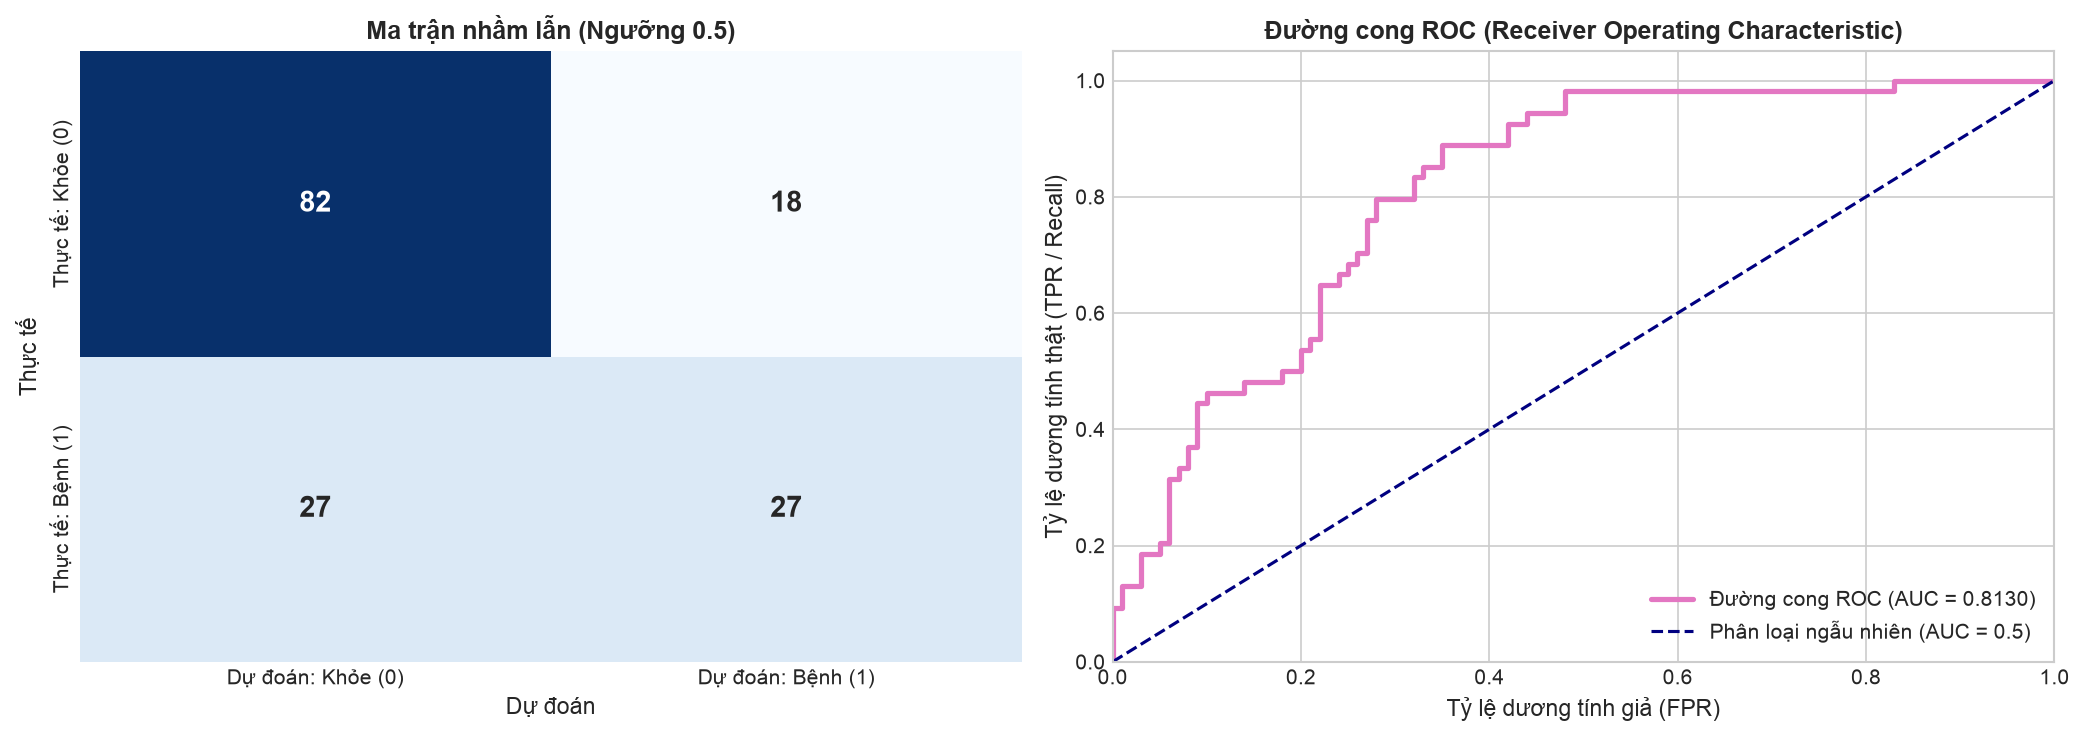

In [6]:
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve

# Dự đoán nhãn cứng (ngưỡng mặc định 0.5) và xác suất liên tục
y_pred = log_reg.predict(X_test_scaled)
y_proba = log_reg.predict_proba(X_test_scaled)[:, 1]

# Ma trận nhầm lẫn
cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:\n", cm)

# Báo cáo chi tiết: Precision, Recall, F1
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=['Lớp 0 (Khỏe)', 'Lớp 1 (Bệnh)']))

# Đo lường diện tích dưới đường cong ROC
auc_score = roc_auc_score(y_test, y_proba)
print(f"ROC-AUC Score: {auc_score:.4f}")

# Trực quan hóa Ma trận nhầm lẫn và Đường cong ROC
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Heatmap Confusion Matrix
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0], cbar=False,
            xticklabels=['Dự đoán: Khỏe (0)', 'Dự đoán: Bệnh (1)'],
            yticklabels=['Thực tế: Khỏe (0)', 'Thực tế: Bệnh (1)'],
            annot_kws={'size': 14, 'weight': 'bold'})
axes[0].set_title("Ma trận nhầm lẫn (Ngưỡng 0.5)", fontsize=12, fontweight='bold')
axes[0].set_ylabel("Thực tế", fontsize=11)
axes[0].set_xlabel("Dự đoán", fontsize=11)

# Đường cong ROC
fpr, tpr, _ = roc_curve(y_test, y_proba)
axes[1].plot(fpr, tpr, color='#e377c2', lw=2.5, label=f'Đường cong ROC (AUC = {auc_score:.4f})')
axes[1].plot([0, 1], [0, 1], color='navy', lw=1.5, linestyle='--', label='Phân loại ngẫu nhiên (AUC = 0.5)')
axes[1].set_xlim([0.0, 1.0])
axes[1].set_ylim([0.0, 1.05])
axes[1].set_xlabel('Tỷ lệ dương tính giả (FPR)', fontsize=11)
axes[1].set_ylabel('Tỷ lệ dương tính thật (TPR / Recall)', fontsize=11)
axes[1].set_title('Đường cong ROC (Receiver Operating Characteristic)', fontsize=12, fontweight='bold')
axes[1].legend(loc='lower right', fontsize=10)

plt.tight_layout()
plt.show()


### Khối 2.6: Khảo sát dịch chuyển ngưỡng quyết định (Threshold Tuning)
* **Thực hiện:** Thay vì dùng ngưỡng mặc định 0.5, chủ động hạ hoặc nâng ngưỡng quyết định $th \in [0.3, 0.4, 0.5, 0.6]$ để dịch chuyển tương quan giữa Precision và Recall.
* **Ý nghĩa thực tế:** Khi hạ ngưỡng xuống 0.3, mô hình nhạy bén hơn rất nhiều trong việc phát hiện mầm bệnh, từ đó kéo giảm số ca bỏ sót ($FN$) xuống mức thấp nhất có thể, bảo vệ tính mạng bệnh nhân.

Ngưỡng   | Recall   | Precision  | F1-Score   | TN   | FP   | FN (Bỏ sót)  | TP  
---------------------------------------------------------------------------
0.3      | 0.7963   | 0.5972     | 0.6825     | 71   | 29   | 11           | 43  
0.4      | 0.6481   | 0.6140     | 0.6306     | 78   | 22   | 19           | 35  
0.5      | 0.5000   | 0.6000     | 0.5455     | 82   | 18   | 27           | 27  
0.6      | 0.4630   | 0.6410     | 0.5376     | 86   | 14   | 29           | 25  


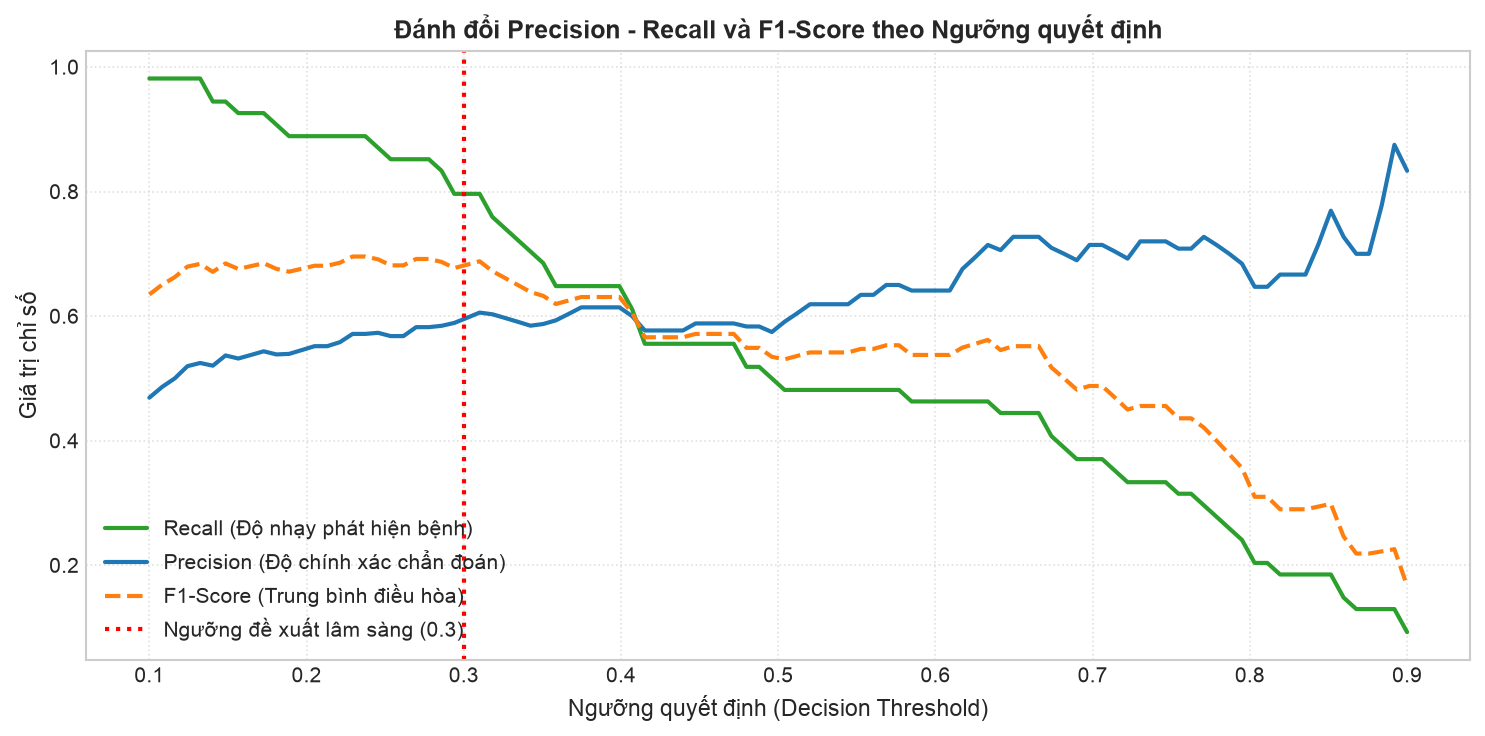

In [7]:
thresholds = [0.3, 0.4, 0.5, 0.6]

print(f"{'Ngưỡng':<8} | {'Recall':<8} | {'Precision':<10} | {'F1-Score':<10} | {'TN':<4} | {'FP':<4} | {'FN (Bỏ sót)':<12} | {'TP':<4}")
print("-" * 75)

for th in thresholds:
    # Gán nhãn 1 nếu xác suất vượt ngưỡng th
    custom_pred = (y_proba >= th).astype(int)
    cm_th = confusion_matrix(y_test, custom_pred)
    tn, fp, fn, tp = cm_th.ravel()
    recall = tp / (tp + fn)
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0
    print(f"{th:<8.1f} | {recall:<8.4f} | {precision:<10.4f} | {f1:<10.4f} | {tn:<4d} | {fp:<4d} | {fn:<12d} | {tp:<4d}")

# Trực quan hóa đường cong đánh đổi Precision - Recall theo ngưỡng
th_dense = np.linspace(0.1, 0.9, 100)
rec_list, prec_list, f1_list, fn_list = [], [], [], []
for t in th_dense:
    p_t = (y_proba >= t).astype(int)
    c_t = confusion_matrix(y_test, p_t)
    tn_t, fp_t, fn_t, tp_t = c_t.ravel()
    r = tp_t / (tp_t + fn_t)
    p = tp_t / (tp_t + fp_t) if (tp_t + fp_t) > 0 else 0
    f = 2 * p * r / (p + r) if (p + r) > 0 else 0
    rec_list.append(r)
    prec_list.append(p)
    f1_list.append(f)
    fn_list.append(fn_t)

plt.figure(figsize=(10, 5))
plt.plot(th_dense, rec_list, label='Recall (Độ nhạy phát hiện bệnh)', color='#2ca02c', lw=2)
plt.plot(th_dense, prec_list, label='Precision (Độ chính xác chẩn đoán)', color='#1f77b4', lw=2)
plt.plot(th_dense, f1_list, label='F1-Score (Trung bình điều hòa)', color='#ff7f0e', lw=2, linestyle='--')
plt.axvline(0.3, color='red', linestyle=':', lw=2, label='Ngưỡng đề xuất lâm sàng (0.3)')
plt.xlabel('Ngưỡng quyết định (Decision Threshold)', fontsize=11)
plt.ylabel('Giá trị chỉ số', fontsize=11)
plt.title('Đánh đổi Precision - Recall và F1-Score theo Ngưỡng quyết định', fontsize=12, fontweight='bold')
plt.legend(loc='lower left', fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()


### Phân tích nâng cao: Ảnh hưởng của Siêu tham số Điều chuẩn C
* **Mặt toán học:** Tham số $C = \frac{1}{\lambda}$ điều khiển sự cân bằng giữa hàm mất mát dữ liệu và số hạng phạt $L_2$:
$$\min_{w, b} \left[ C \sum_{i=1}^N \text{LogLoss}(y_i, \hat{p}_i) + \frac{1}{2} \|w\|_2^2 \right]$$
* Dưới đây ta chạy thực nghiệm đối chứng ảnh hưởng của $C$ đến độ chính xác và độ lớn trọng số $\|w\|_2$:

In [8]:
c_exp = [0.0001, 0.001, 0.01, 0.1, 1.0, 10.0, 100.0, 1000.0]
print(f"{'C':<10} | {'Train Acc':<10} | {'Test Acc':<10} | {'Train AUC':<10} | {'Test AUC':<10} | {'||w||_2':<10}")
print("-" * 65)

for c_val in c_exp:
    m = LogisticRegression(C=c_val, solver='lbfgs', max_iter=1000, random_state=42)
    m.fit(X_train_scaled, y_train)
    tr_acc = m.score(X_train_scaled, y_train)
    te_acc = m.score(X_test_scaled, y_test)
    tr_auc = roc_auc_score(y_train, m.predict_proba(X_train_scaled)[:, 1])
    te_auc = roc_auc_score(y_test, m.predict_proba(X_test_scaled)[:, 1])
    w_norm = np.linalg.norm(m.coef_)
    print(f"{c_val:<10.4f} | {tr_acc:<10.4f} | {te_acc:<10.4f} | {tr_auc:<10.4f} | {te_auc:<10.4f} | {w_norm:<10.4f}")


C          | Train Acc  | Test Acc   | Train AUC  | Test AUC   | ||w||_2   
-----------------------------------------------------------------
0.0001     | 0.6515     | 0.6494     | 0.8350     | 0.7828     | 0.0228    
0.0010     | 0.6596     | 0.6558     | 0.8373     | 0.7863     | 0.1806    
0.0100     | 0.7801     | 0.7403     | 0.8465     | 0.7985     | 0.6832    
0.1000     | 0.7899     | 0.6883     | 0.8509     | 0.8104     | 1.2458    
1.0000     | 0.7964     | 0.7078     | 0.8502     | 0.8130     | 1.4486    
10.0000    | 0.7964     | 0.7078     | 0.8500     | 0.8130     | 1.4765    
100.0000   | 0.7964     | 0.7078     | 0.8500     | 0.8131     | 1.4794    
1000.0000  | 0.7964     | 0.7078     | 0.8500     | 0.8131     | 1.4797    


### Nhận xét và Kết luận Bài toán 2:
1. **Khả năng phân loại tổng thể:** Mô hình đạt **ROC-AUC = 0.8130**, chứng minh khả năng phân biệt bệnh nhân mắc bệnh và người khỏe mạnh rất tốt. Thuộc tính `Glucose` ($w = +1.1444$) và `BMI` ($w = +0.6481$) có trọng số dương lớn nhất, phản ánh tương thích với y văn: nồng độ glucose máu và chỉ số khối cơ thể là hai chỉ báo hàng đầu của bệnh tiểu đường.
2. **Tại sao ngưỡng mặc định 0.5 chưa tối ưu:**
   * Ở ngưỡng 0.5: Recall chỉ đạt **50.00%**, có tới **27/54 ca mắc bệnh bị bỏ sót ($FN=27$)**! Trong bối cảnh y tế, việc để lọt 50% người có bệnh ra về mà không được điều trị kịp thời là một rủi ro y khoa nghiêm trọng.
3. **Đề xuất chọn ngưỡng cắt $th = 0.3$:**
   * Khi hạ ngưỡng xuống **0.3**:
     * Recall tăng vọt lên **79.63%** (phát hiện được 43/54 ca bệnh).
     * Số ca bỏ sót giảm mạnh từ 27 xuống chỉ còn **11 ca** (giảm gần 60% số ca bỏ sót).
     * Điểm F1-Score đạt đỉnh cao nhất trong tất cả các ngưỡng: **0.6825**.
     * Precision vẫn được duy trì ở mức chấp nhận được: **59.72%** (người nghi ngờ bệnh chỉ cần làm thêm xét nghiệm khẳng định huyết học với chi phí thấp).
4. **Ý nghĩa của hệ số $C$:**
   * Khi $C \to 0$ ($C=0.0001$): $\|w\|_2 \approx 0.0228$, trọng số bị ép triệt tiêu, mô hình rơi vào **Underfitting** (độ chính xác bằng đúng tỷ lệ mẫu đa số 65.15%).
   * Khi $C$ ở mức vừa phải ($C=1.0$): đạt độ cân bằng tối ưu giữa Regularization và Loss fitting.
